# 03 · Neural network

Your turn. Implement `build_neural_net` in `src/train.py`, then use this notebook to train it and compare it against the baselines.

Checklist:

- [ ] A small network: 2 hidden `Dense` layers with ReLU, one sigmoid output.
- [ ] `BinaryCrossentropy` loss, Adam optimizer.
- [ ] Train with `class_weight` and `validation_data=(X_cv, y_cv)`.
- [ ] Plot J_train vs J_cv per epoch. High bias or high variance?
- [ ] Add the network to the comparison table and the PR curve.

In [1]:
# Reload src/ automatically, so edits to src/train.py show up without restarting the kernel.
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))  # make `src` importable from notebooks/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Fixed colors: blue is always "legit", orange is always "fraud".
LEGIT, FRAUD = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=[LEGIT, FRAUD, "#1baf7a", "#eda100"]),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 110,
})

In [2]:
import tensorflow as tf

from src.data import load_raw, split_by_time
from src.evaluate import confusion, evaluate, plot_pr_curves, results_table
from src.features import Preprocessor
from src.train import build_neural_net, train_logistic

tf.random.set_seed(42)  # reproducible weight initialization

In [3]:
split = split_by_time(load_raw())
prep = Preprocessor().fit(split.train)
X_train, y_train = prep.transform(split.train)
X_cv, y_cv = prep.transform(split.cv)

## Build the model

In [4]:
model = build_neural_net(n_features=X_train.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │           248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

## Train

TODO: choose the fraud weight. A good first guess is the class ratio (legit / fraud in train), then try smaller values.

In [5]:


# Train the model
FRAUD_WEIGHT = 400  # weight fraud cases more heavily
cv_weights = np.where(y_cv == 1, FRAUD_WEIGHT, 1)  # weight fraud cases more heavily
history = model.fit(
    X_train, y_train,
    validation_data=(X_cv, y_cv, cv_weights),
    class_weight={0: 1, 1: FRAUD_WEIGHT},
    epochs=100, batch_size=512,
)

Epoch 1/100


  1/334 ━━━━━━━━━━━━━━━━━━━━ 2:13 402ms/step - loss: 1.4296 - pr_auc: 0.0013

114/334 ━━━━━━━━━━━━━━━━━━━━ 0s 443us/step - loss: 1.4987 - pr_auc: 0.0021  

291/334 ━━━━━━━━━━━━━━━━━━━━ 0s 345us/step - loss: 1.3901 - pr_auc: 0.0025

334/334 ━━━━━━━━━━━━━━━━━━━━ 1s 765us/step - loss: 1.4092 - pr_auc: 0.0025 - val_loss: 0.8779 - val_pr_auc: 0.0018


...

Epoch 100/100


  1/334 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0856 - pr_auc: 1.0000

150/334 ━━━━━━━━━━━━━━━━━━━━ 0s 400us/step - loss: 0.2002 - pr_auc: 0.7488

307/334 ━━━━━━━━━━━━━━━━━━━━ 0s 358us/step - loss: 0.2047 - pr_auc: 0.7640

334/334 ━━━━━━━━━━━━━━━━━━━━ 0s 472us/step - loss: 0.2066 - pr_auc: 0.7552 - val_loss: 0.2716 - val_pr_auc: 0.7515


## Learning curves: J_train vs J_cv

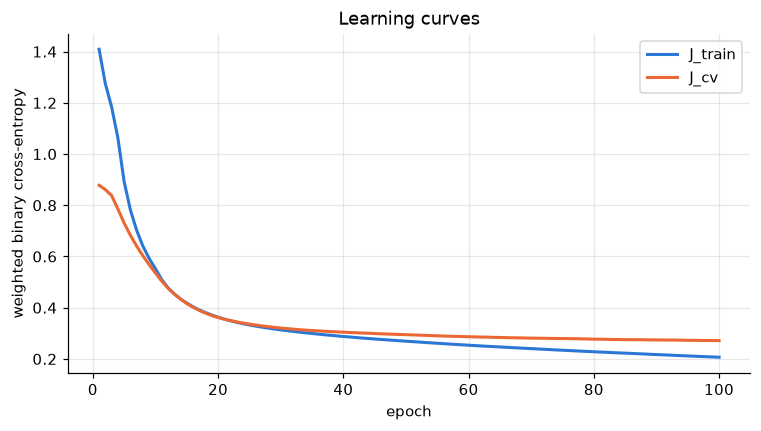

In [6]:
train_loss = history.history["loss"]
cv_loss = history.history["val_loss"]
epochs = range(1, len(train_loss) + 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(epochs, train_loss, lw=2, label="J_train")
ax.plot(epochs, cv_loss, lw=2, label="J_cv")
ax.set_xlabel("epoch")
ax.set_ylabel("weighted binary cross-entropy")
ax.set_title("Learning curves")
ax.legend()
fig.savefig(FIGURES / "nn_learning_curves.png", bbox_inches="tight")

## Compare with the baseline

In [7]:
# The baselines are retrained on the same split, so every model is scored on the same cv set.
# The lazy model is left out: its PR curve is the dashed "random" line in the plot below.
baselines = {
    "logistic": train_logistic(X_train, y_train),
    "logistic (balanced)": train_logistic(X_train, y_train, class_weight="balanced"),
}
probs = {name: m.predict_proba(X_cv)[:, 1] for name, m in baselines.items()}
probs["neural net"] = model.predict(X_cv, verbose=0).ravel()

results_table({name: evaluate(y_cv, p) for name, p in probs.items()})

,accuracy,precision,recall,f1,pr_auc,roc_auc
neural net,0.9769,0.0361,0.8596,0.0692,0.7667,0.9622
logistic (balanced),0.9611,0.0226,0.8947,0.0440,0.7616,0.9721
logistic,0.9992,0.6429,0.4737,0.5455,0.6287,0.9687


Where do the neural net's errors fall at the default 0.5 threshold?

In [8]:
confusion(y_cv, probs["neural net"])

,pred: legit,pred: fraud
actual: legit,55594,1310
actual: fraud,8,49


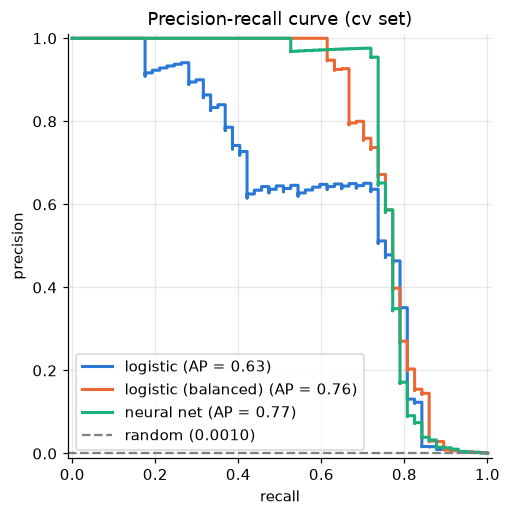

In [9]:
ax = plot_pr_curves(y_cv, probs)
ax.figure.savefig(FIGURES / "pr_curve_comparison.png", bbox_inches="tight")

## Conclusions

TODO (you): answer in a few sentences.

1. Learning curves: high bias, high variance, or neither? Back it up with what the plot shows.
2. Does the neural net beat the balanced logistic regression on PR-AUC? By how much?
3. Looking at the PR curve: in which recall range is each model better?
4. What would you try next, and why?